# Puntos de calor de la NASA en Bolivia: primeros pasos

**NASA Space Apps Challenge Sucre 2026** · material de la charla "¿Qué hay detrás de un punto rojo en el mapa?" (Christian Conchari).

Este notebook te lleva en ~15 minutos de cero a tus primeras gráficas con datos reales de la NASA:

1. Descargar los puntos de calor de Bolivia (MODIS y VIIRS) **sin cuenta ni clave**.
2. Entender qué dice cada columna.
3. Ver la temporada de incendios.
4. Ver la trampa del cambio de sensor (el "salto de 2012").
5. Una primera armonización simple (desafío de armonización MODIS–VIIRS).
6. Una primera prueba de tendencia (desafío Trend Detective).

Funciona en Google Colab o en tu computadora (Python 3.10+). Todo en español; los nombres de columnas son los originales de FIRMS.

## 0. Preparación
Solo necesitamos `pandas`, `matplotlib` y `pymannkendall` (para la prueba de tendencia).

In [1]:
# En Colab descomenta la línea siguiente:
# !pip install -q pymannkendall

import os, io, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.spines.top": False, "axes.spines.right": False})
COLOR_MODIS, COLOR_VIIRS, COLOR_SUMA = "#2a78d6", "#eb6834", "#1baf7a"

## 1. Descargar los datos

FIRMS (*Fire Information for Resource Management System*) publica **archivos anuales por país** que se descargan directo, sin cuenta:

- MODIS (satélites Terra y Aqua, píxel de 1 km): desde 2000.
- VIIRS (satélite Suomi NPP, píxel de 375 m): desde 2012.

Son datos del **archivo estándar** (reprocesados y consistentes): los correctos para tendencias.

> Para datos de los últimos días usa la API de FIRMS con una MAP_KEY gratuita (https://firms.modaps.eosdis.nasa.gov/api/). La API devuelve pocos días por consulta; para años, usa estos archivos anuales o *Archive Download*.

La celda guarda los archivos en `firms_cache/` para no descargarlos dos veces. VIIRS pesa más (2024 son ~70 MB): la primera vez puede tardar unos minutos.

In [2]:
PAIS = "Bolivia"
CACHE = "firms_cache"
os.makedirs(CACHE, exist_ok=True)
URL = "https://firms.modaps.eosdis.nasa.gov/data/country/{sensor}/{anio}/{sensor}_{anio}_{pais}.csv"
COLUMNAS = ["latitude", "longitude", "acq_date", "acq_time", "satellite", "confidence", "frp", "daynight", "type"]

def descargar(sensor, anios):
    partes = []
    for anio in anios:
        archivo = os.path.join(CACHE, f"{sensor}_{anio}_{PAIS}.csv")
        if not os.path.exists(archivo):
            print("descargando", sensor, anio, "...")
            urllib.request.urlretrieve(URL.format(sensor=sensor, anio=anio, pais=PAIS), archivo)
        partes.append(pd.read_csv(archivo, usecols=COLUMNAS))
    df = pd.concat(partes, ignore_index=True)
    df["acq_date"] = pd.to_datetime(df["acq_date"])
    return df

modis = descargar("modis", range(2001, 2026))
viirs = descargar("viirs-snpp", range(2012, 2026))
print(f"MODIS: {len(modis):,} filas · VIIRS: {len(viirs):,} filas")

MODIS: 1,837,089 filas · VIIRS: 3,847,525 filas


## 2. ¿Qué dice cada fila?

Cada fila es **un píxel donde el satélite vio algo muy caliente** en el momento en que pasó:

| Columna | Qué significa |
|---|---|
| `latitude`, `longitude` | Centro del píxel |
| `acq_date`, `acq_time` | Fecha y hora del paso, **en UTC** (Bolivia = UTC−4) |
| `satellite` | Terra / Aqua (MODIS) o N = Suomi NPP (VIIRS) |
| `confidence` | Seguridad del algoritmo: MODIS 0–100; VIIRS l / n / h (baja, nominal, alta). **No es una probabilidad.** |
| `frp` | Potencia radiativa del fuego, en MW: qué tan fuerte arde |
| `daynight` | D = día, N = noche |
| `type` | 0 = incendio de vegetación · 1 = volcán · 2 = otra fuente fija (industria) · 3 = mar adentro |

Un punto de calor **no** es un incendio de 1 km²: un fuego de ~1 ha puede activar un píxel entero.

In [3]:
viirs.head()

,latitude,longitude,acq_date,acq_time,satellite,confidence,frp,daynight,type
0,-16.78363,-60.66871,2012-01-20,453,N,n,0.80,N,0
1,-16.16069,-64.76305,2012-01-20,453,N,n,1.71,N,0
2,-16.16146,-64.75935,2012-01-20,453,N,n,1.14,N,0
3,-16.68112,-62.61004,2012-01-20,453,N,n,1.38,N,0
4,-16.77500,-60.26242,2012-01-20,453,N,n,0.86,N,0


In [4]:
# Nos quedamos solo con incendios de vegetación
modis = modis[modis["type"] == 0]
viirs = viirs[viirs["type"] == 0]

## 3. La temporada de incendios

Contamos puntos por mes del año. En Bolivia la temporada seca va de julio a octubre.

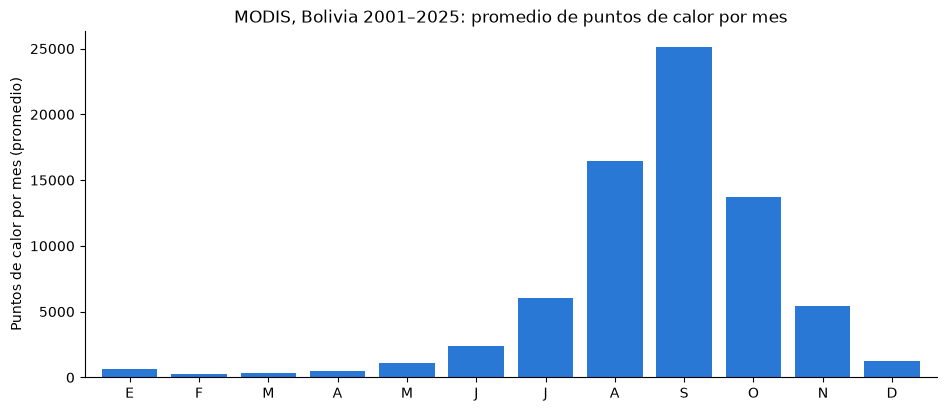

In [5]:
meses = ["E", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
por_mes = modis.groupby(modis["acq_date"].dt.month).size() / modis["acq_date"].dt.year.nunique()
ax = por_mes.plot(kind="bar", color=COLOR_MODIS, width=0.8)
ax.set_xticklabels(meses, rotation=0)
ax.set_xlabel("")
ax.set_ylabel("Puntos de calor por mes (promedio)")
ax.set_title("MODIS, Bolivia 2001–2025: promedio de puntos de calor por mes")
plt.show()

## 4. La trampa: un cambio de sensor parece una tendencia

Si sumamos MODIS y VIIRS, en 2012 "aparece" muchísimo más fuego. No es más fuego: es que entró un sensor que ve fuegos más pequeños.

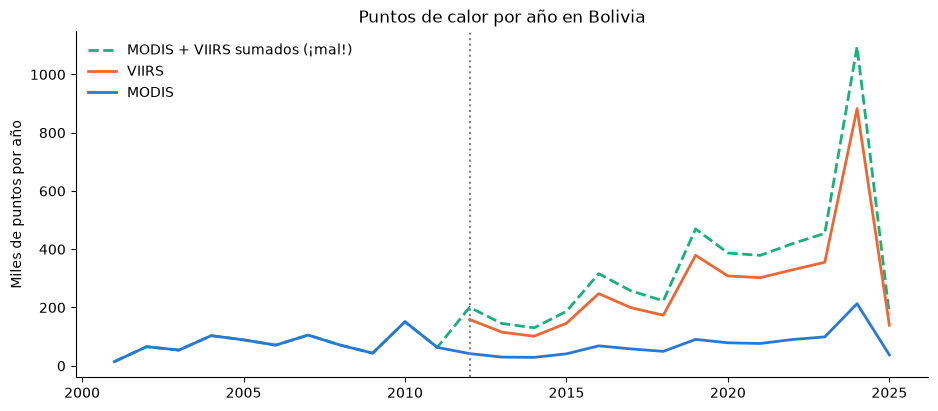

VIIRS / MODIS por año: {2012: 3.81, 2013: 3.88, 2014: 3.53, 2015: 3.56, 2016: 3.62, 2017: 3.45, 2018: 3.52, 2019: 4.19, 2020: 3.91, 2021: 3.95, 2022: 3.66, 2023: 3.59, 2024: 4.14, 2025: 3.72}


In [6]:
anual_m = modis.groupby(modis["acq_date"].dt.year).size()
anual_v = viirs.groupby(viirs["acq_date"].dt.year).size()
suma = anual_m.add(anual_v, fill_value=0)

ax = plt.gca()
ax.plot(suma.index, suma / 1e3, color=COLOR_SUMA, ls="--", lw=2, label="MODIS + VIIRS sumados (¡mal!)")
ax.plot(anual_v.index, anual_v / 1e3, color=COLOR_VIIRS, lw=2, label="VIIRS")
ax.plot(anual_m.index, anual_m / 1e3, color=COLOR_MODIS, lw=2, label="MODIS")
ax.axvline(2012, color="gray", ls=":")
ax.set_ylabel("Miles de puntos por año")
ax.set_title("Puntos de calor por año en Bolivia")
ax.legend(frameon=False)
plt.show()

razon = (anual_v / anual_m).dropna()
print("VIIRS / MODIS por año:", razon.round(2).to_dict())

**Observa:** la razón VIIRS/MODIS es bastante estable (≈3,5–4,2). Eso sugiere que se puede llevar VIIRS a la "escala MODIS" con un factor, calculado en los años en que ambos funcionan (2012 en adelante).

## 5. Primera armonización (desafío de armonización MODIS–VIIRS)

Idea simple, para empezar (no es la solución final):

1. Calcular un factor por **mes del año** con el periodo de solapamiento (la razón cambia con la estación).
2. Dividir VIIRS entre ese factor → VIIRS "en escala MODIS".
3. Validar: en los años de solapamiento, ¿se parece a MODIS?

Mejoras que puedes probar después: factores por región (Chaco, Chiquitanía, Amazonía), separar día y noche, comparar solo pasadas cercanas en hora (Aqua y VIIRS cruzan cerca del mediodía), y trabajar con una cuadrícula de "hubo fuego sí/no" (sección 5b).

Factor VIIRS/MODIS por mes: {1: 3.58, 2: 3.76, 3: 3.42, 4: 3.5, 5: 3.29, 6: 3.45, 7: 3.3, 8: 3.85, 9: 3.74, 10: 3.69, 11: 4.41, 12: 3.8}
Validación 2020–2025: diferencia total VIIRS armonizado vs MODIS = +3.8%


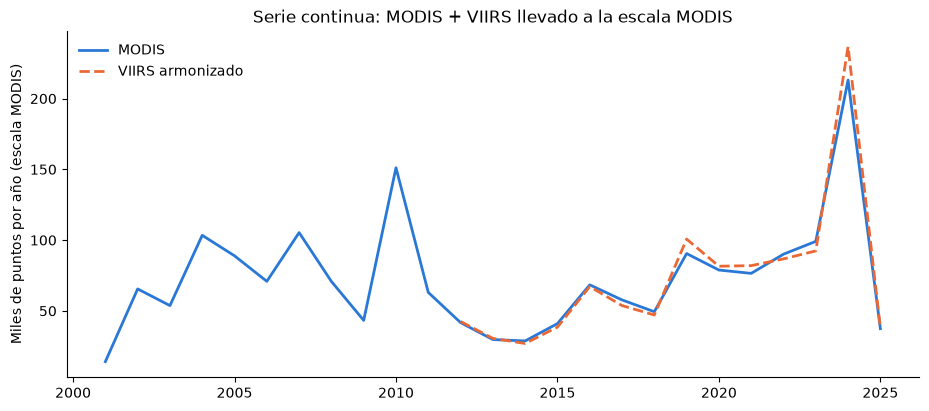

In [7]:
mm = modis.groupby([modis["acq_date"].dt.year.rename("anio"), modis["acq_date"].dt.month.rename("mes")]).size()
mv = viirs.groupby([viirs["acq_date"].dt.year.rename("anio"), viirs["acq_date"].dt.month.rename("mes")]).size()
tabla = pd.DataFrame({"modis": mm, "viirs": mv}).fillna(0)

# Calibramos con 2012–2019 y validamos con 2020–2025 (¡nunca validar con los mismos datos!)
cal = tabla.loc[2012:2019]
factor = cal.groupby("mes")["viirs"].sum() / cal.groupby("mes")["modis"].sum()
print("Factor VIIRS/MODIS por mes:", factor.round(2).to_dict())

tabla["viirs_en_escala_modis"] = tabla["viirs"] / tabla.index.get_level_values("mes").map(factor).values
val = tabla.loc[2020:2025]
err = (val["viirs_en_escala_modis"].sum() - val["modis"].sum()) / val["modis"].sum()
print(f"Validación 2020–2025: diferencia total VIIRS armonizado vs MODIS = {err:+.1%}")

anual = tabla.groupby("anio")[["modis", "viirs_en_escala_modis"]].sum()
ax = anual["modis"].div(1e3).plot(color=COLOR_MODIS, lw=2, label="MODIS")
anual["viirs_en_escala_modis"].loc[2012:].div(1e3).plot(ax=ax, color=COLOR_VIIRS, lw=2, ls="--", label="VIIRS armonizado")
ax.set_ylabel("Miles de puntos por año (escala MODIS)")
ax.set_xlabel("")
ax.set_title("Serie continua: MODIS + VIIRS llevado a la escala MODIS")
ax.legend(frameon=False)
plt.show()

### 5b. Cuadrícula de "hubo fuego sí/no"

Contar puntos favorece al sensor con píxel más chico. Una alternativa: dividir el mapa en cuadrados de 0,25° (~25 km) y marcar **1 si hubo al menos un punto ese día**. Así los dos sensores "cuentan" parecido.

In [8]:
def celdas_dia(df, tam=0.25):
    celda = (np.floor(df["latitude"] / tam).astype(int).astype(str) + "_" +
             np.floor(df["longitude"] / tam).astype(int).astype(str))
    return pd.DataFrame({"celda": celda, "dia": df["acq_date"]}).drop_duplicates()

cm = celdas_dia(modis.loc[modis["acq_date"].dt.year >= 2012])
cv = celdas_dia(viirs)
am = cm.groupby(cm["dia"].dt.year).size()
av = cv.groupby(cv["dia"].dt.year).size()
print("Razón VIIRS/MODIS con conteo de puntos:      ", round((anual_v / anual_m).loc[2012:].median(), 2))
print("Razón VIIRS/MODIS con celdas-día con fuego:  ", round((av / am).median(), 2))

Razón VIIRS/MODIS con conteo de puntos:       3.69
Razón VIIRS/MODIS con celdas-día con fuego:   1.99


La razón baja mucho: con celdas-día los dos sensores se parecen más. Es una forma más robusta de comparar (aunque pierde información de intensidad; para eso está el `frp`).

## 6. ¿Hay una tendencia? (desafío Trend Detective)

Pasos:
1. Serie mensual (aquí, puntos de calor MODIS para usar 25 años con un solo sensor).
2. **Anomalía** = cada mes menos el promedio de ese mes. Así quitamos la temporada.
3. Prueba de **Mann-Kendall estacional** (no supone que los datos sean normales) y **pendiente de Sen** (cuánto cambia por año).

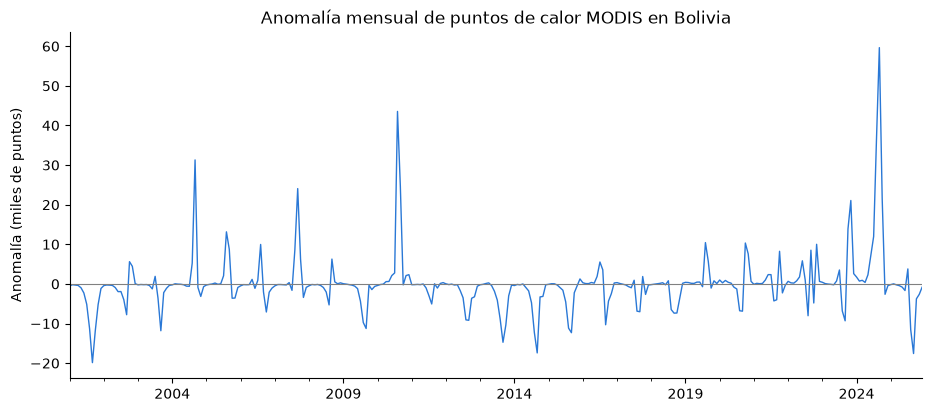

Mann-Kendall estacional: tendencia = increasing, p = 0.000, pendiente de Sen = +30.0 puntos por año (para un mismo mes)


In [9]:
mensual = modis.set_index("acq_date").resample("MS").size()
mensual = mensual.reindex(pd.date_range("2001-01-01", "2025-12-01", freq="MS"), fill_value=0)
anomalia = mensual - mensual.groupby(mensual.index.month).transform("mean")

ax = anomalia.div(1e3).plot(color=COLOR_MODIS, lw=1)
ax.axhline(0, color="gray", lw=0.8)
ax.set_ylabel("Anomalía (miles de puntos)")
ax.set_title("Anomalía mensual de puntos de calor MODIS en Bolivia")
plt.show()

try:
    import pymannkendall as mk
    r = mk.seasonal_test(mensual.values, period=12)
    print(f"Mann-Kendall estacional: tendencia = {r.trend}, p = {r.p:.3f}, pendiente de Sen = {r.slope:+.1f} puntos por año (para un mismo mes)")
except ImportError:
    print("Instala pymannkendall:  pip install pymannkendall")

**Cómo leerlo:** si `p < 0,05` hay evidencia de tendencia. Ojo:
- Los incendios dependen mucho de años extremos (2010, 2019, 2024): una tendencia puede venir de pocos años.
- Si pruebas muchas regiones a la vez, corrige por comparaciones múltiples.
- Un día sin puntos no es un cero seguro: pudo estar nublado.

## 7. Siguientes pasos

| Quiero… | Usa |
|---|---|
| Temperatura de superficie | MODIS LST (MOD11C3) vía [AppEEARS](https://appeears.earthdatacloud.nasa.gov) o `earthaccess` |
| Lluvia | GPM IMERG, en [Giovanni](https://giovanni.gsfc.nasa.gov) (sin código) |
| Humedad del suelo | SMAP (desde 2015) |
| Vegetación | MODIS NDVI (MOD13) |
| Clima por punto, rápido | [NASA POWER](https://power.larc.nasa.gov) (API sin clave) |
| Ver imágenes del día | [Worldview](https://worldview.earthdata.nasa.gov) |
| Puntos de calor recientes | API de [FIRMS](https://firms.modaps.eosdis.nasa.gov/api/) con MAP_KEY (NOAA-20 / NOAA-21) |

**Antes del 14:** crea tu cuenta en [Earthdata Login](https://urs.earthdata.nasa.gov) y tu MAP_KEY de FIRMS, elige desafío y escribe tu pregunta en una línea.

Ejemplo rápido con NASA POWER (temperatura mensual de un punto de la Chiquitanía):

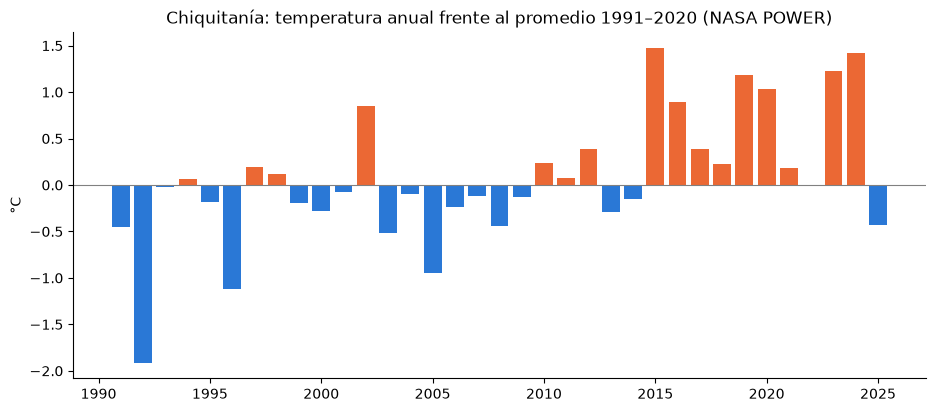

In [10]:
import json
url = ("https://power.larc.nasa.gov/api/temporal/monthly/point?parameters=T2M&community=AG"
       "&longitude=-61.5&latitude=-17.0&start=1991&end=2025&format=JSON")
datos = json.load(urllib.request.urlopen(url))["properties"]["parameter"]["T2M"]
anual_t = pd.Series({int(k[:4]): v for k, v in datos.items() if k.endswith("13") and v != -999})
anom_t = anual_t - anual_t.loc[1991:2020].mean()
ax = plt.gca()
ax.bar(anom_t.index, anom_t.values, color=[COLOR_VIIRS if v > 0 else COLOR_MODIS for v in anom_t.values])
ax.axhline(0, color="gray", lw=0.8)
ax.set_ylabel("°C")
ax.set_title("Chiquitanía: temperatura anual frente al promedio 1991–2020 (NASA POWER)")
plt.show()

---
Datos: NASA FIRMS (MODIS C6.1, VIIRS 375 m, archivo estándar), NASA POWER. ¡Mucho éxito en el hackatón!